# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

In [1]:
# Preliminares
import pandas as pd

from src.modeling import (
    cargar_datos_clean, remover_pares_restantes, separar_datos_live,
    categorizar_en_cuantiles
    )
from src.transform import encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots 
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 967 entries, 2007-04-30 to 2026-11-02
Data columns (total 71 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   EURUSD_return                        967 non-null    float64
 1   GBPUSD_return                        967 non-null    float64
 2   USDJPY_return                        967 non-null    float64
 3   USDCAD_return                        967 non-null    float64
 4   USDCHF_return                        967 non-null    float64
 5   AUDUSD_return                        967 non-null    float64
 6   EURUSD_return_lag1                   967 non-null    float64
 7   GBPUSD_return_lag1                   967 non-null    float64
 8   USDJPY_return_lag1                   967 non-null    float64
 9   USDCHF_return_lag1                   967 non-null    float64
 10  AUDUSD_return_lag1                   967 non-null    float64
 11  EURUSD_range1

## Analisis de variables

In [2]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

In [11]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "_position_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
EURUSD_range10_position_lag1,967.0,-0.015760,0.756970,-1.0,-0.805190,-0.010515,0.747535,1.0
GBPUSD_range10_position_lag1,967.0,0.013015,0.739109,-1.0,-0.725806,0.063197,0.717287,1.0
USDJPY_range10_position_lag1,967.0,0.066786,0.751912,-1.0,-0.688552,0.105264,0.851357,1.0
USDCAD_range10_position_lag1,967.0,0.041416,0.752884,-1.0,-0.718629,0.065958,0.814706,1.0
USDCHF_range10_position_lag1,967.0,-0.059838,0.748467,-1.0,-0.828434,-0.114170,0.663446,1.0
AUDUSD_range10_position_lag1,967.0,0.022550,0.761363,-1.0,-0.745619,0.049620,0.818343,1.0


In [4]:
# Asimetrias general
mostrar_asimetrias(df_clean)

USDCAD_return                          3.254278
VIX_level                              2.358869
USDCAD_var20_lag1_log                  2.010929
GBPUSD_High_Low_spread_lag1_log        1.386586
USDJPY_High_Low_spread_lag1_log        1.239797
USDCHF_var20_lag1_log                  1.077862
EURUSD_High_Low_spread_lag1_log        0.871121
Oil_var20_lag1_log                     0.789492
USDJPY_Open_pct_diff_last_Close_yeo    0.749393
USDCHF_High_Low_spread_lag1_log        0.682570
USDJPY_High_pct_diff_Close_lag1_yeo    0.649098
GBPUSD_var20_lag1_log                  0.617579
Gold_Volume_pct_diff_sma20_lag1_yeo    0.583137
USDCAD_High_Low_spread_lag1_log        0.570616
AUDUSD_sma15_pct_diff_sma50_lag1       0.562723
USDJPY_sma15_pct_diff_sma50_lag1       0.529410
SPY_Open_pct_diff_last_Close_yeo       0.476938
AUDUSD_High_Low_spread_lag1_log        0.432432
DXY_pct_chg_20d                        0.391511
Oil_Open_pct_diff_last_Close_yeo       0.374105
Oil_return_lag1                        0

In [5]:
# Asimetria por grupo
cadena = "Open_pct_diff_last_Close"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

USDJPY_Open_pct_diff_last_Close_yeo    0.749393
SPY_Open_pct_diff_last_Close_yeo       0.476938
Oil_Open_pct_diff_last_Close_yeo       0.374105
EURUSD_Open_pct_diff_last_Close_yeo    0.085936
USDCHF_Open_pct_diff_last_Close_yeo   -0.036826
Gold_Open_pct_diff_last_Close_yeo     -0.047009
GBPUSD_Open_pct_diff_last_Close_yeo   -0.311226
USDCAD_Open_pct_diff_last_Close_yeo   -0.623456
AUDUSD_Open_pct_diff_last_Close_yeo   -0.849467


Cont


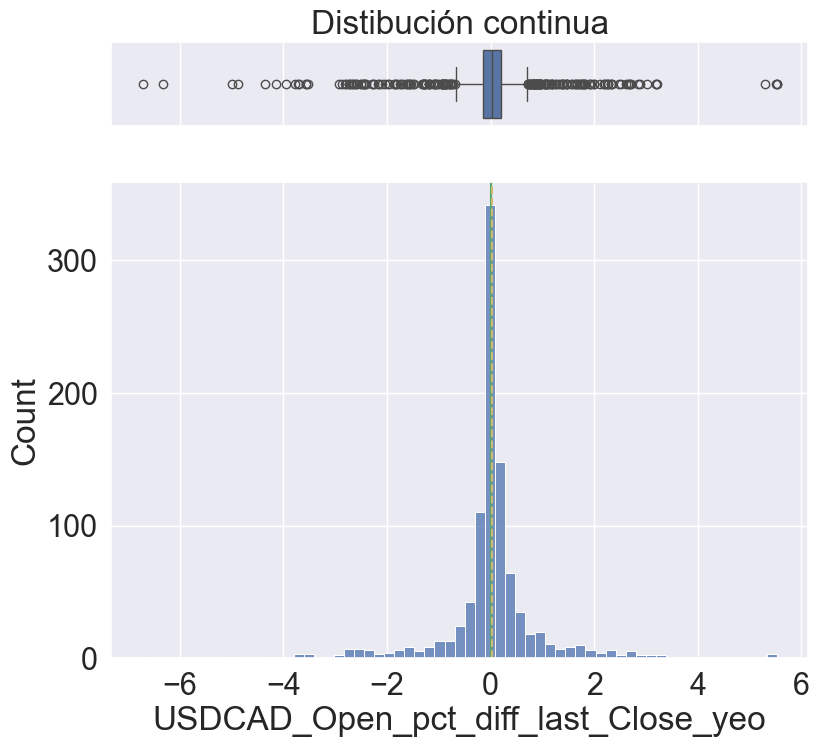

In [6]:
# Visualizar columna
col = 'USDCAD_Open_pct_diff_last_Close_yeo'
pintar_columna(df_clean[col])

In [7]:
# Tabla de Correlaciones
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
249,AUDUSD_sma15_pct_diff_sma50_lag1,USDCAD_sma15_pct_diff_sma50_lag1,0.833161
202,USDCHF_sma15_pct_diff_sma50_lag1,EURUSD_sma15_pct_diff_sma50_lag1,0.785197
997,GBPUSD_High_pct_diff_Close_lag1_yeo,GBPUSD_return_lag1,0.768128
1043,USDJPY_High_pct_diff_Close_lag1_yeo,USDJPY_return_lag1,0.751127
776,USDCHF_var20_lag1_log,EURUSD_var20_lag1_log,0.750390
1475,USDCHF_Low_pct_diff_Close_lag1_yeo,EURUSD_High_pct_diff_Close_lag1_yeo,0.749594
182,USDCHF_range10_position_lag1,EURUSD_range10_position_lag1,0.745823
1273,EURUSD_Low_pct_diff_Close_lag1_yeo,USDCHF_High_pct_diff_Close_lag1_yeo,0.743000
1231,EURUSD_Low_pct_diff_Close_lag1_yeo,EURUSD_return_lag1,0.717248
952,EURUSD_High_pct_diff_Close_lag1_yeo,EURUSD_return_lag1,0.713697


## Analisis de labels

In [8]:
simbolo_objetivo = 'EURUSD'
# Cargar fichero de precios
df = cargar_datos_clean()
df = remover_pares_restantes(df,simbolo_objetivo)

# Separar datos de entrenamiento y test  
ultima_fecha = df.index.max()
df_train, df_live = separar_datos_live(df=df, fecha=ultima_fecha)

# Se crea la variable categorica a partir del dataset de entrenamiento
# Variable objetivo: se crea variable categorica por cuantiles
objetivo = f"{simbolo_objetivo}_return"
objetivo_cat = f"{objetivo}_cat"

df_train, tabla_bins = categorizar_en_cuantiles(
    df_train, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=True
    )


print(f"\n--- Rangos por Categoría para el ticker {simbolo_objetivo} ---")
print(tabla_bins)


--- Rangos por Categoría para el ticker EURUSD ---
   categoria  lim_inferior  lim_superior
0          1     -0.042661     -0.004675
1          2     -0.004675      0.004651
2          3      0.004651      0.044001


In [9]:
df_train[objetivo_cat].value_counts()

EURUSD_return_cat
1    322
2    322
3    322
Name: count, dtype: int64

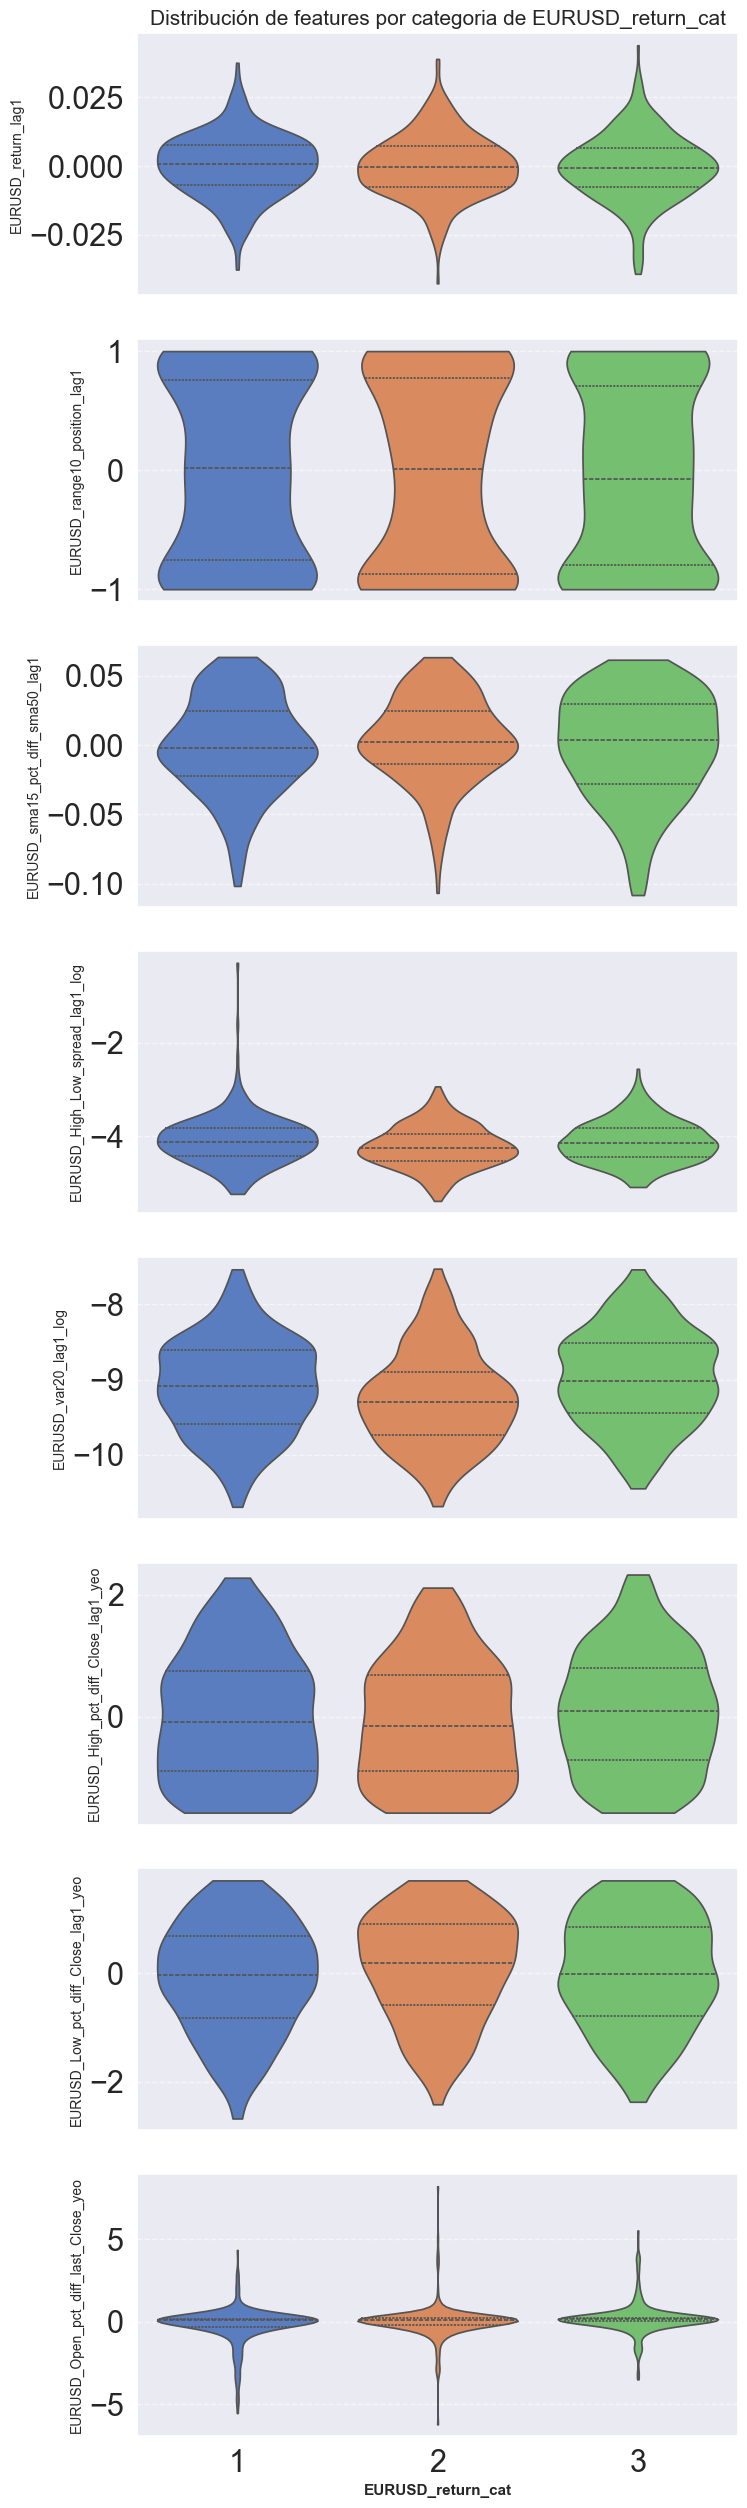

In [10]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_train.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]

# Filtrar por grupo de variables
cadena = "EURUSD"
columnas = encontrar_columnas(columnas_target=numeric_cols, cadena=cadena)

pintar_violin_plots(
    df=df_train,
    numeric_cols=columnas,
    target_col=target_col
)